# <h1>Tutorial Extractor, Translator & LaTeX Publisher Pipeline</h1>

*An automated, enterprise-grade research and publishing workflow built with LangChain, LangGraph, and Google Gemini (`gemini-3.6-flash`). This notebook extracts technical tutorials from single or multi-page documentation sites, cleans and proofreads the content, performs optional multilingual translation, typesets the result into standalone compilable LaTeX with PDF bookmarks and strict margin overflow controls, and packages everything into local directories and `.rar` archives.*

---

## 💡 Executive Summary & Architectural Rationale

### Purpose
Manually copying online coding tutorials, cleaning up extraneous web headers/ads, translating them into other languages, and formatting them into professional typeset PDFs or clean Markdown references is a tedious, error-prone task. This pipeline automates the entire lifecycle:
1. **Extraction**: Crawls and parses target webpages using robust fallback scrapers (`httpx` + headless Playwright).
2. **Standardization & Proofreading**: Cleans boilerplate, compiles multi-page table-of-contents into unified documents, and passes text through an LLM technical editor to fix typos and grammatical flaws.
3. **Multilingual Translation**: Translates technical tutorials into target languages (e.g., Japanese, Portuguese) while preserving code blocks and relative asset paths.
4. **LaTeX Typesetting**: Converts Markdown into professional LaTeX articles complete with syntax-highlighted code blocks (`lstlistings`), strict word-breaking (`xurl`, `seqsplit`), and clickable document bookmarks.
5. **Disk Persistence & Checkpointing**: Persists state JSON snapshots on disk (supporting local storage and mounted Google Drive directories), enabling granular resume capabilities after rate limits or interruptions.

### Key Strengths
- **Granular Checkpointing & Resumption**: Supports node-level and chunk-level caching (`checkpoint.json`). If quotas or network errors interrupt execution midway through a 50,000-character document, previously processed chunks and completed nodes are preserved, resuming instantly where it left off.
- **Robust Layout Protection**: Solves classic LaTeX margin overflow problems by wrapping inline monospaced strings, CamelCase identifiers, and underscored names in `\seqsplit` and enabling `xurl` line breaks.
- **LLM Provider Flexibility**: Uses a centralized factory helper (`get_llm()`) that decouples model instantiation, allowing instant switching between Google Gemini, OpenAI, Anthropic, or Groq.

### Known Limitations
- **API Rate Limits & Quotas**: Heavy web scraping and large document chunk processing consume significant LLM tokens. Daily provider free-tier quotas can be exhausted quickly when processing massive multi-page documentation hubs.
- **Dynamic Content & Paywalls**: Pages protected by aggressive Cloudflare CAPTCHAs or requiring authenticated user logins may fail or require manual session cookies in Playwright.
- **LaTeX CJK Engine Constraints**: Standard `pdflatex` compilers require specific input encodings or specialized CJK wrappers (`CJKutf8`) to render non-Latin scripts (Japanese/Chinese/Korean) without dropping characters.

<!--
# https://realpython.com/python-pydantic/
# https://playwright.dev/python/docs/intro
# https://jeroenjanssens.com/dsatcl/
-->

## <h2>1. Dependencies & Environment Setup</h2>

This section installs and initializes the foundational libraries, headless browsers, and system utilities required by the pipeline:

- **`langchain-google-genai`**: The official LangChain integration library for connecting to Google Gemini models (e.g., `gemini-3.6-flash`).
- **`langgraph`**: Orchestrates the stateful, multi-node sequential pipeline graph and manages state transitions.
- **`httpx` & `playwright`**: Power the resilient dual-layer web scraping infrastructure (fast asynchronous HTTP fetching backed by headless Chromium automation).
- **`beautifulsoup4`**: Parses and cleans raw HTML document structures before text extraction.
- **`pydantic`**: Enforces strict data validation schemas for state management and structured LLM extractions.
- **`nest_asyncio`**: Permits nested `asyncio` event loops inside interactive Google Colab notebook environments.
- **`rarfile` & System Utilities (`rar`/`unrar`)**: Bundles final markdown, LaTeX documents, and local image assets into clean, downloadable `.rar` archives.

> **Note on Browser & OS Binaries**: We execute `!playwright install chromium` along with `!apt-get install -y unrar rar` to ensure that headless browser binaries and file compression utilities are fully available in the Linux runtime environment.

In [1]:
# Package Installation

!pip install -qU langgraph beautifulsoup4 pydantic httpx nest_asyncio playwright rarfile
!pip install -qU langchain-google-genai
# !pip install -qU langchain-openai
# !pip install -qU langchain-anthropic
# !pip install -qU langchain-ollama
# !pip install -qU langchain_aws
# !pip install -qU langchain-groq
!playwright install chromium
!playwright install-deps chromium
!apt-get install -y unrar rar

Installing dependencies...
Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:4 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:5 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libasound2t64 is already the newest version (1.2.11-1ubuntu0.3).
libatk-bridge2.0-0t64 is already the newest version (2.52.0-1build1).
libatk1.

In [2]:
# Package Imports & Environment Configuration

import asyncio
import json
import os
import re
import shutil
import subprocess
from pathlib import Path
from typing import Dict, List, Optional, Union
from urllib.parse import urljoin, urlparse

import httpx
from bs4 import BeautifulSoup
from google.colab import drive, userdata
from langchain_core.prompts import ChatPromptTemplate
from langchain_google_genai import ChatGoogleGenerativeAI
# from langchain_openai import ChatOpenAI
# from langchain_anthropic import ChatAnthropic
# from langchain_ollama import ChatOllama
# from langchain_aws import ChatBedrockConverse
# from langchain_groq import ChatGroq
from langgraph.graph import END, StateGraph
from playwright.async_api import async_playwright
from pydantic import BaseModel, Field

In [3]:
# Mount Google Drive for persistent storage
mount_drive = True

if mount_drive:
  drive.mount("/content/drive")
  DRIVE_OUTPUT_DIR = Path("/content/drive/My Drive/Colab Notebooks")
else:
  DRIVE_OUTPUT_DIR = Path("./tutorial_output")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## <h2>2. Core State Schemas & Checkpoint Persistence Architecture</h2>

This section establishes the data structures and disk persistence mechanisms that power the pipeline's **fault tolerance and resumability**:

1. **Pydantic Data Models**:
   - `CorrectionDetail` & `ProofreadOutputModel`: Structure validation outputs during technical editing.
   - `SinglePageExtractionModel`: Enforces strict extraction schemas for article titles, authors, publication dates, and cleaned body Markdown.
   - `TutorialPipelineState`: Maintains the global state shared across all LangGraph nodes (tracking URLs, scraped pages, compiled/proofread/translated markdown, LaTeX strings, error states, and intra-node chunk dictionaries).
2. **Disk Checkpointing (`save_checkpoint` & `load_checkpoint`)**:
   - Every time a node finishes a page or chunk, state is serialized to `checkpoint.json` inside the specified `output_dir`.
   - Using `model_dump(mode = "json")` and `default = str` ensures that `pathlib.Path` objects and intermediate states serialize cleanly without throwing JSON TypeError exceptions.

In [4]:
# State Schema & Helper Functions

class CorrectionDetail(BaseModel):
  """
  Record of a grammar/spelling correction made during proofreading.
  """

  original_text: str = Field(description = "The snippet with the error")
  corrected_text: str = Field(description = "The corrected snippet")
  explanation: str = Field(description = "Brief reason for the correction")

class ProofreadOutputModel(BaseModel):
  """
  Output schema for the proofreading node.
  """

  corrected_markdown: str = Field(
    description = "The cleaned and corrected Markdown content"
  )
  corrections: List[CorrectionDetail] = Field(
    default_factory = list, description = "List of corrections made"
  )

class SinglePageExtractionModel(BaseModel):
  """
  Pydantic extraction schema for individual tutorial sub-pages.
  """

  page_title: str = Field(
    description = "Title of this tutorial section"
  )
  author: Optional[str] = Field(
    default = None,
    description = "Author name if available"
  )
  publication_date: Optional[str] = Field(
    default = None,
    description = "Publication or last updated date if available"
  )
  section_markdown: str = Field(
    description = (
      "Clean article body strictly formatted in Markdown. Preserve all"
      " image tags as HTML or Markdown."
    )
  )

class TutorialPipelineState(BaseModel):
  """
  State model for the Tutorial Processing Graph.
  """

  # Input configuration
  urls_input: Union[str, List[str], Dict[int, Dict[str, str]]] = Field(
    description = "URL string, list of URLs, or structured discovery dict"
  )
  perform_translation: bool = Field(default = False)
  source_language: str = Field(default = "English")
  target_language: str = Field(default = "Japanese")
  save_to_disk: bool = Field(default = True)
  output_dir: Union[str, Path] = Field(default = "./tutorial_output")

  # Intermediate and final state fields
  target_urls: List[str] = Field(
    default_factory = list,
    description = "Resolved ordered list of target URLs"
  )
  scraped_pages: List[dict] = Field(default_factory = list)
  compiled_markdown: str = Field(default = "")
  proofread_markdown: str = Field(default = "")
  proofreading_report: List[dict] = Field(default_factory = list)
  proofread_chunks: Dict[str, str] = Field(default_factory = dict)
  translated_markdown: str = Field(default = "")
  translated_chunks: Dict[str, str] = Field(default_factory = dict)
  latex_content: str = Field(default = "")
  latex_chunks: Dict[str, str] = Field(default_factory = dict)
  archive_path: Optional[str] = Field(default = None)
  error: Optional[str] = Field(default = None)

def get_val(state, key: str, default = None):
  """
  Safe getter for state parameters whether state is dict or Pydantic instance.
  """

  if isinstance(state, dict):
    return state.get(key, default)
  return getattr(state, key, default)

def _clean_llm_markdown(content) -> str:
  """
  Safely converts LLM response content to string and strips markdown code fence wrappers.
  """

  if isinstance(content, list):
    text = "".join(
      block if isinstance(block, str) else block.get("text", "")
      for block in content
    )
  else:
    text = str(content)

  text = text.strip()
  if text.startswith("```"):
    text = re.sub(r"^```[a-zA-Z]*\n?", "", text)
    text = re.sub(r"\n?```$", "", text)
  return text.strip()


# Checkpoint Serialization Helpers

def save_checkpoint(state: TutorialPipelineState) -> None:
  """
  Saves the current pipeline state to checkpoint.json in output_dir.
  """

  output_dir = Path(get_val(state, "output_dir", "./tutorial_output"))
  output_dir.mkdir(parents = True, exist_ok = True)
  checkpoint_file = output_dir / "checkpoint.json"

  # mode="json" forces Pydantic to convert Path/PosixPath objects to string primitives
  if hasattr(state, "model_dump"):
    state_dict = state.model_dump(mode = "json")
  else:
    state_dict = dict(state)

  # default=str acts as a fallback for any non-serializable objects
  with open(checkpoint_file, "w", encoding = "utf-8") as f:
    json.dump(state_dict, f, indent = 2, ensure_ascii = False, default = str)

def load_checkpoint(output_dir: str) -> Optional[dict]:
  """
  Loads checkpoint.json from output_dir if it exists.
  """

  checkpoint_file = Path(output_dir) / "checkpoint.json"
  if checkpoint_file.exists():
    try:
      with open(checkpoint_file, "r", encoding = "utf-8") as f:
        return json.load(f)
    except Exception as e:
      print(f"Warning: Could not read checkpoint file: {e}")
  return None

In [5]:
# LLM Provider Configuration

LLM_PROVIDER = "google"  # Options: "google", "openai", "anthropic", "groq", "ollama"

LLM_CONFIGS = {
  "google": {
    "class": ChatGoogleGenerativeAI,
    "model": "gemini-3.6-flash",
    "api_key_env": "GOOGLE_API_KEY",
    "key_param": "google_api_key"
  },
  # "openai": {
  #   "class": ChatOpenAI,
  #   "model": "gpt-4o-mini",
  #   "api_key_env": "OPENAI_API_KEY",
  #   "key_param": "api_key"
  # },
  # "anthropic": {
  #   "class": ChatAnthropic,
  #   "model": "claude-3-5-haiku-20241022",
  #   "api_key_env": "ANTHROPIC_API_KEY",
  #   "key_param": "api_key"
  # },
  # "groq": {
  #   "class": ChatGroq,
  #   "model": "llama-3.3-70b-versatile",
  #   "api_key_env": "GROQ_API_KEY",
  #   "key_param": "api_key"
  # }
}

def get_llm(temperature: float = 0.0):
  """
  Factory function to instantiate the configured LLM provider.
  """

  if LLM_PROVIDER not in LLM_CONFIGS:
    raise ValueError(f"Unsupported/unconfigured LLM provider: {LLM_PROVIDER}")

  cfg = LLM_CONFIGS[LLM_PROVIDER]
  cls = cfg["class"]
  model_name = cfg["model"]
  api_key = userdata.get(cfg["api_key_env"])

  kwargs = {"model": model_name, "temperature": temperature}
  if cfg["key_param"] and api_key:
    kwargs[cfg["key_param"]] = api_key

  return cls(**kwargs)

## <h2>3. Dual-Layer Web Scraping & Image Downloader</h2>

Robust data acquisition is critical for web scraping because many modern technical tutorial sites implement anti-bot protections (such as Cloudflare or JavaScript rendering gates). This section implements a resilient dual-layer fetching and asset-handling strategy:

- **`_scrape_with_playwright(...)`**: A headless Chromium browser automation fallback. It launches Playwright with anti-detection flags (`--disable-blink-features=AutomationControlled`, `--no-sandbox`) to render JavaScript-heavy, dynamic single-page applications or sites blocking standard HTTP requests.
- **`async_fetch_html(...)`**: The primary high-performance HTTP fetcher powered by `httpx`. It attempts a fast asynchronous HTTP request first. If it encounters a status code indicating blocking (`401` or `403`), or if a timeout/network exception occurs, it automatically falls back to Playwright.
- **`download_image_asset(...)`**: Scans extracted Markdown for remote image links (`![]()`), downloads the binary asset via `httpx`, saves it locally into an `images/` directory, and rewrites the markdown links to point to local relative paths. This ensures that generated `.rar` archives and LaTeX documents remain fully self-contained offline.

In [6]:
# Web Scraper & Image Downloader

async def _scrape_with_playwright(url: str, timeout: int = 20) -> str:
  """
  Headless Playwright scraper fallback for dynamic pages or anti-bot protection.
  """

  async with async_playwright() as p:
    browser = await p.chromium.launch(
      headless = True,
      args = ["--disable-blink-features=AutomationControlled", "--no-sandbox"]
    )
    context = await browser.new_context(
      user_agent = (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
        " (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36"
      ),
      locale = "en-US",
    )
    page = await context.new_page()
    try:
      await page.goto(
        url, wait_until = "domcontentloaded", timeout = 1000 * timeout
      )
      await page.wait_for_timeout(2000)
      html_content = await page.content()
    finally:
      await browser.close()
  return html_content

async def async_fetch_html(url: str, timeout: int = 15) -> str:
  """
  Fetches raw HTML via httpx, falling back to Playwright on block/failure.
  """

  headers = {
    "User-Agent": (
      "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
      " (KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36"
    ),
    "Accept": (
      "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8"
    ),
  }
  try:
    async with httpx.AsyncClient(follow_redirects = True) as client:
      response = await client.get(url, headers = headers, timeout = timeout)
      if response.status_code in [401, 403]:
        return await _scrape_with_playwright(url, timeout = timeout)
      response.raise_for_status()
      return response.text
  except Exception:
    return await _scrape_with_playwright(url, timeout = timeout)

async def download_image_asset(
    img_url: str, save_dir: Path, timeout: int = 15
) -> Optional[str]:
  """
  Downloads an image locally and returns the relative image path.
  """

  headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
  }
  try:
    parsed = urlparse(img_url)
    filename = os.path.basename(parsed.path)
    if not filename or not re.search(
        r"\.(png|jpg|jpeg|gif|svg|webp)$", filename, re.I
      ):
      filename = f"img_{abs(hash(img_url))}.png"

    local_file_path = save_dir / filename
    async with httpx.AsyncClient(follow_redirects = True) as client:
      resp = await client.get(img_url, headers = headers, timeout = timeout)
      resp.raise_for_status()
      local_file_path.write_bytes(resp.content)
      return f"images/{filename}"
  except Exception:
    return None

## <h2>4. Link Discovery & LangGraph Pipeline Nodes</h2>

The pipeline is organized as a sequential directed graph in LangGraph, moving data step-by-step through 6 specialized nodes:

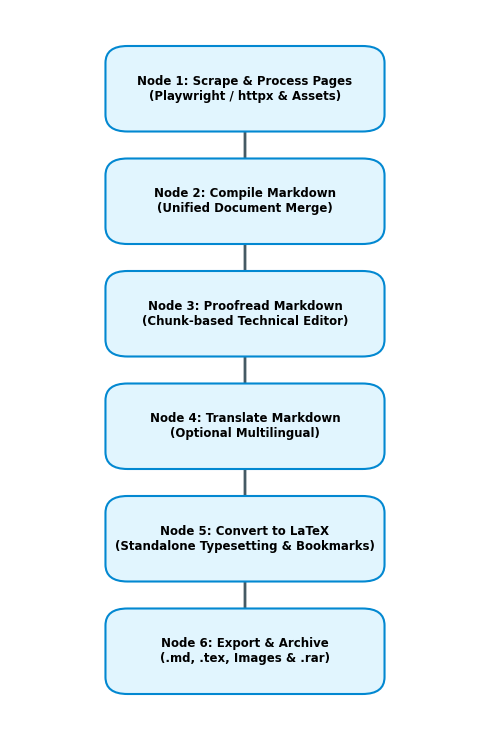

In [7]:
# @title Pipeline Architecture Flowchart { display-mode: "form" }

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import networkx as nx

# Initialize Directed Graph
G = nx.DiGraph()

# Nodes & Descriptions
nodes = {
  "scrape": "Node 1: Scrape & Process Pages\n(Playwright / httpx & Assets)",
  "compile": "Node 2: Compile Markdown\n(Unified Document Merge)",
  "proofread": "Node 3: Proofread Markdown\n(Chunk-based Technical Editor)",
  "translate": "Node 4: Translate Markdown\n(Optional Multilingual)",
  "latex": "Node 5: Convert to LaTeX\n(Standalone Typesetting & Bookmarks)",
  "export": "Node 6: Export & Archive\n(.md, .tex, Images & .rar)"
}

# Add Edges (Linear sequence)
edges = [
  ("scrape", "compile", ""),
  ("compile", "proofread", ""),
  ("proofread", "translate", ""),
  ("translate", "latex", ""),
  ("latex", "export", "")
]

# Vertical Stack Layout (Centered X = 0)
pos = {
  "scrape": (0, 5.0),
  "compile": (0, 4.0),
  "proofread": (0, 3.0),
  "translate": (0, 2.0),
  "latex": (0, 1.0),
  "export": (0, 0.0)
}

# Set figure dimensions (narrower width)
plt.figure(figsize = (5.0, 7.5))
ax = plt.gca()

# Draw Edges first so they sit behind the rectangular nodes
nx.draw_networkx_edges(
    G,
    pos,
    edgelist = [(u, v) for u, v, w in edges],
    arrowstyle = "-|>",
    arrowsize = 18,
    edge_color = "#455a64",
    width = 2,
    ax = ax,
)

# Draw Custom Wide Rectangular Nodes using FancyBboxPatch
box_width = 1.50
box_height = 0.36

for node, (x, y) in pos.items():
  # Create a rounded rectangular box centered at (x, y)
  rect = patches.FancyBboxPatch(
    (x - box_width / 2, y - box_height / 2),
    box_width,
    box_height,
    boxstyle = "round,pad=0.2,rounding_size=0.15",
    facecolor = "#e1f5fe",
    edgecolor = "#0288d1",
    linewidth = 1.5
  )
  ax.add_patch(rect)

# Draw Node Text Labels inside the rectangles
node_labels = {k: nodes[k] for k in pos}
nx.draw_networkx_labels(
  G,
  pos,
  labels = node_labels,
  font_size = 8.5,
  font_family = "sans-serif",
  font_weight = "bold",
  ax = ax
)

# Set explicit plot boundaries to keep it compact and centered
plt.xlim(-1.6, 1.6)
plt.ylim(-0.7, 5.7)
plt.axis("off")
plt.tight_layout()
plt.show()

### <h3>Detailed Node Breakdown:</h3>
1. **Node 1 (`scrape_and_process_pages_node`)**: Resolves input URLs, fetches raw HTML via `httpx` (falling back to headless Playwright if blocked), strips unnecessary navigational clutter (footers, headers, scripts), converts embedded widgets into Markdown blockquotes, extracts clean article text via structured LLM extraction, downloads remote images locally, and saves checkpoints immediately after each page.
2. **Node 2 (`compile_markdown_node`)**: Aggregates all extracted sub-pages into a single unified Markdown document separated by horizontal rules, prepending source links, author attribution, and publication dates to each section header.
3. **Node 3 (`proofread_markdown_node`)**: Checks document length against `CHUNK_THRESHOLD`. If large, splits text at H2 heading boundaries (`\n## `) and proofreads sections iteratively. Uses intra-node checkpointing (`proofread_chunks`) so that if quota limits hit on chunk 3 of 5, chunks 1 and 2 are preserved.
4. **Node 4 (`translate_markdown_node`)**: If `perform_translation = True`, translates the tutorial into the target language chunk by chunk, preserving code blocks, image paths, and structural headers.
5. **Node 5 (`convert_to_latex_node`)**: Transforms Markdown into professional LaTeX. Enforces core publishing packages (`graphicx`, `hyperref`, `listings`, `xcolor`, `geometry`, `bookmark`, `parskip`, `xurl`, `seqsplit`, `microtype`), manages code block language mapping (`[language=python]`, etc.), wraps long monospaced/CamelCase identifiers in `\seqsplit`, and handles large documents via header/fragment splitting.
6. **Node 6 (`export_files_and_archive_node`)**: Writes `tutorial.md` and `tutorial.tex` to disk, organizes local images, and executes a system `rar` command to bundle everything into `tutorial_package.rar`.

In [8]:
# Standalone Link Discovery Tools

async def async_discover_tutorial_urls(
  root_url: str,
  toc_selector: Optional[str] = None
) -> Dict[int, Dict[str, str]]:
  """
  Extracts tutorial URLs and page/link titles into a 1-indexed structured dictionary.
  """

  if not toc_selector:
    try:
      html = await async_fetch_html(root_url)
      soup = BeautifulSoup(html, "html.parser")
      title_tag = soup.find("title") or soup.find("h1")
      title = (
        title_tag.get_text(strip = True) if title_tag else "Main Tutorial Page"
      )
    except Exception:
      title = "Main Tutorial Page"
    return {1: {"link": root_url, "title": title}}

  try:
    html = await async_fetch_html(root_url)
    soup = BeautifulSoup(html, "html.parser")
    links = soup.select(toc_selector)

    discovered = {}
    seen_urls = set()
    order = 1

    for a_tag in links:
      href = a_tag.get("href")
      # Ignore empty anchors, '#' toggles, or javascript links
      if href and href != "#" and not href.startswith("javascript:"):
        abs_url = urljoin(root_url, href)
        if abs_url not in seen_urls:
          seen_urls.add(abs_url)
          link_title = a_tag.get_text(strip = True) or f"Section {order}"
          discovered[order] = {"link": abs_url, "title": link_title}
          order += 1

    if not discovered:
      discovered = {1: {"link": root_url, "title": "Main Tutorial Page"}}

    return discovered
  except Exception as e:
    print(f"Error during link discovery: {e}")
    return {1: {"link": root_url, "title": "Main Tutorial Page"}}

def discover_tutorial_urls(
  root_url: str,
  toc_selector: Optional[str] = None
) -> Dict[int, Dict[str, str]]:
  """
  Synchronous Colab wrapper for async_discover_tutorial_urls.
  """

  import nest_asyncio

  nest_asyncio.apply()

  try:
    loop = asyncio.get_running_loop()
  except RuntimeError:
    loop = None

  if loop and loop.is_running():
    return loop.run_until_complete(
      async_discover_tutorial_urls(root_url, toc_selector)
    )
  else:
    return asyncio.run(async_discover_tutorial_urls(root_url, toc_selector))


# Pipeline Node Definitions

async def scrape_and_process_pages_node(state: TutorialPipelineState) -> dict:
  """
  Node 1: Scrapes target pages, skipping URLs already completed in checkpoint.
  """

  if get_val(state, "error"):
    return {}

  raw_input = get_val(state, "urls_input")

  target_urls = []
  if isinstance(raw_input, dict):
    for k in sorted(raw_input.keys()):
      target_urls.append(raw_input[k]["link"])
  elif isinstance(raw_input, list):
    target_urls = raw_input
  elif isinstance(raw_input, str):
    target_urls = [raw_input]

  output_dir = Path(get_val(state, "output_dir", "./tutorial_output"))
  img_dir = output_dir / "images"
  img_dir.mkdir(parents = True, exist_ok = True)

  # Check existing scraped pages from checkpoint
  existing_pages = get_val(state, "scraped_pages", [])
  scraped_urls = {p["url"] for p in existing_pages if "url" in p}

  scraped_pages = list(existing_pages)

  # Identify remaining URLs to scrape
  urls_to_scrape = [u for u in target_urls if u not in scraped_urls]

  if not urls_to_scrape:
    print(
      f"All {len(target_urls)} pages already extracted in checkpoint."
      " Skipping scraping."
    )
    return {"target_urls": target_urls, "scraped_pages": scraped_pages}

  print(
    f"Extracting {len(urls_to_scrape)} / {len(target_urls)} remaining"
    " pages..."
  )

  llm = get_llm(temperature = 0.0)
  structured_llm = llm.with_structured_output(SinglePageExtractionModel)

  prompt = ChatPromptTemplate.from_messages([
    (
      "system",
      (
        "You are an expert web tutorial extractor. Extract the FULL main"
        " tutorial content from the provided HTML text.\n"
        "1. Extract the page title, author, and date if available.\n"
        "2. Exclude headers, footers, sidebars, and advertisements.\n"
        "3. Extract EVERY SINGLE article paragraph without skipping any"
        " text, especially text preceding interactive widgets,"
        " code blocks, or figures.\n"
        "4. Preserve images as markdown tags ![alt](url) and embedded"
        " widgets/iframes as blockquotes with their full title and"
        " link.\n"
        "5. Do NOT skip explanatory intro paragraphs before widgets or"
        " diagrams."
      ),
    ),
    ("human", "Web Page Content:\n\n{web_content}")
  ])
  chain = prompt | structured_llm

  for url in urls_to_scrape:
    try:
      print(f"  -> Scraping: {url}")
      raw_html = await async_fetch_html(url)
      soup = BeautifulSoup(raw_html, "html.parser")

      for widget in soup.find_all(["widget-embed", "iframe"]):
        src = widget.get("src") or widget.get("data-src")
        title = widget.get("title", "Interactive Widget")
        if src:
          abs_src = urljoin(url, src)
          widget_placeholder = soup.new_tag("p")
          widget_placeholder.string = (
            f"\n\n> **[Interactive Widget: {title}]({abs_src})**\n\n"
          )
          widget.replace_with(widget_placeholder)

      for tag in soup.find_all(
        ["script", "style", "nav", "footer", "header", "noscript", "aside"]
      ):
        tag.decompose()

      body = soup.find("article") or soup.find("main") or soup.find("body")
      cleaned_html = str(body) if body else str(soup)

      extracted: SinglePageExtractionModel = await chain.ainvoke(
        {"web_content": cleaned_html}
      )
      md_text = extracted.section_markdown

      img_urls = re.findall(r"!\[.*?\]\((https?://[^\s\)]+)\)", md_text)
      for img_url in img_urls:
        local_rel_path = await download_image_asset(img_url, img_dir)
        if local_rel_path:
          md_text = md_text.replace(img_url, local_rel_path)

      scraped_pages.append({
        "title": extracted.page_title,
        "author": extracted.author,
        "publication_date": extracted.publication_date,
        "markdown": md_text,
        "url": url
      })

      # Save checkpoint immediately after every page extraction!
      temp_state = TutorialPipelineState(
        urls_input = raw_input,
        target_urls = target_urls,
        scraped_pages = scraped_pages,
        output_dir = str(output_dir)
      )
      save_checkpoint(temp_state)

    except Exception as e:
      err_msg = f"Failed scraping page {url}: {str(e)}"
      temp_state = TutorialPipelineState(
        urls_input = raw_input,
        target_urls = target_urls,
        scraped_pages = scraped_pages,
        output_dir = str(output_dir),
        error = err_msg
      )
      save_checkpoint(temp_state)
      return {"error": err_msg}

  return {"target_urls": target_urls, "scraped_pages": scraped_pages}

async def compile_markdown_node(state: TutorialPipelineState) -> dict:
  """
  Node 2: Compiles Markdown, reusing checkpoint if already present.
  """

  if get_val(state, "error"):
    return {}

  if get_val(state, "compiled_markdown"):
    print("Compiled Markdown already exists in checkpoint. Skipping.")
    return {}

  pages = get_val(state, "scraped_pages", [])
  if not pages:
    return {"error": "No scraped pages found to compile."}

  sections = []
  for i, page in enumerate(pages, 1):
    title = page.get("title", f"Section {i}")
    author = page.get("author")
    pub_date = page.get("publication_date")
    page_url = page.get("url", "")
    body = page.get("markdown", "")

    header_block = f"# {title}\n"
    meta_parts = []
    if page_url:
      meta_parts.append(f"**Source:** [{page_url}]({page_url})")
    if author:
      meta_parts.append(f"**Author:** {author}")
    if pub_date:
      meta_parts.append(f"**Published:** {pub_date}")

    if meta_parts:
      header_block += " *|* ".join(meta_parts) + "\n\n"

    sections.append(f"{header_block}{body}")

  unified_markdown = "\n\n---\n\n".join(sections)

  # Checkpoint update
  res_dict = {"compiled_markdown": unified_markdown}
  save_checkpoint(TutorialPipelineState(**{**dict(state), **res_dict}))
  return res_dict

async def proofread_markdown_node(state: TutorialPipelineState) -> dict:
  """
  Node 3: Proofreads Markdown in manageable chunks with intra-node chunk checkpointing.
  """

  if get_val(state, "error"):
    return {}

  if get_val(state, "proofread_markdown"):
    print("Proofread Markdown already exists in checkpoint. Skipping.")
    return {}

  compiled_md = get_val(state, "compiled_markdown", "")
  if not compiled_md:
    return {"proofread_markdown": ""}

  # Retrieve existing partial chunks from state if recovering from a crash
  existing_chunks = get_val(state, "proofread_chunks", {})
  all_corrections = get_val(state, "proofreading_report", [])

  CHUNK_THRESHOLD = 12000
  if len(compiled_md) > CHUNK_THRESHOLD:
    raw_sections = re.split(r"(\n(?=## ))", compiled_md)
    sections = []
    curr = ""
    for piece in raw_sections:
      if len(curr) + len(piece) > CHUNK_THRESHOLD and curr.strip():
        sections.append(curr)
        curr = piece
      else:
        curr += piece
    if curr.strip():
      sections.append(curr)
  else:
    sections = [compiled_md]

  llm = get_llm(temperature = 0.0)
  structured_llm = llm.with_structured_output(ProofreadOutputModel)

  prompt = ChatPromptTemplate.from_messages([
    (
      "system",
      (
        "You are an expert technical editor. Proofread the provided"
        " Markdown section.\n"
        "1. Fix any typos, grammatical mistakes, or awkward phrasing.\n"
        "2. Maintain all code blocks, image paths (images/...), and"
        " Markdown headers intact.\n"
        "3. Provide a list of all corrections made with explanations."
      ),
    ),
    ("human", "{markdown_content}")
  ])
  chain = prompt | structured_llm

  for idx, sec in enumerate(sections):
    chunk_key = str(idx)
    if chunk_key in existing_chunks:
      print(
        f"  -> Proofread chunk {idx + 1}/{len(sections)} restored from"
        " checkpoint."
      )
      continue

    print(f"  -> Proofreading chunk {idx + 1}/{len(sections)}...")
    try:
      result: ProofreadOutputModel = await chain.ainvoke(
        {"markdown_content": sec}
      )
      existing_chunks[chunk_key] = result.corrected_markdown
      all_corrections.extend([c.model_dump() for c in result.corrections])

      # Save checkpoint immediately after each chunk
      temp_state = TutorialPipelineState(
        **{
          **dict(state),
          "proofread_chunks": existing_chunks,
          "proofreading_report": all_corrections
        }
      )
      save_checkpoint(temp_state)
    except Exception as e:
      err_msg = f"Proofreading failed at chunk {idx + 1}: {str(e)}"
      temp_state = TutorialPipelineState(
        **{
          **dict(state),
          "proofread_chunks": existing_chunks,
          "proofreading_report": all_corrections,
          "error": err_msg
        }
      )
      save_checkpoint(temp_state)
      return {"error": err_msg}

  # All chunks complete -> reconstruct full document
  ordered_chunks = [existing_chunks[str(i)] for i in range(len(sections))]
  full_proofread_md = "\n\n".join(ordered_chunks)

  res_dict = {
    "proofread_markdown": full_proofread_md,
    "proofreading_report": all_corrections,
    "proofread_chunks": {}  # Clear temp chunks
  }
  save_checkpoint(TutorialPipelineState(**{**dict(state), **res_dict}))
  return res_dict

async def translate_markdown_node(state: TutorialPipelineState) -> dict:
  """
  Node 4: Translates Markdown in chunks with intra-node chunk checkpointing.
  """

  if get_val(state, "error"):
    return {}

  if get_val(state, "translated_markdown"):
    print("Translated Markdown already exists in checkpoint. Skipping.")
    return {}

  text = get_val(state, "proofread_markdown") or get_val(
    state, "compiled_markdown", ""
  )
  if not get_val(state, "perform_translation", False):
    res_dict = {"translated_markdown": text}
    save_checkpoint(TutorialPipelineState(**{**dict(state), **res_dict}))
    return res_dict

  existing_chunks = get_val(state, "translated_chunks", {})

  CHUNK_THRESHOLD = 15000
  if len(text) > CHUNK_THRESHOLD:
    raw_sections = re.split(r"(\n(?=## ))", text)
    sections = []
    curr = ""
    for piece in raw_sections:
      if len(curr) + len(piece) > CHUNK_THRESHOLD and curr.strip():
        sections.append(curr)
        curr = piece
      else:
        curr += piece
    if curr.strip():
      sections.append(curr)
  else:
    sections = [text]

  source_lang = get_val(state, "source_language", "English")
  target_lang = get_val(state, "target_language", "Japanese")

  llm = get_llm(temperature = 0.0)

  prompt = ChatPromptTemplate.from_messages([
    (
      "system",
      (
        "You are an expert technical translator. Translate the provided"
        " Markdown section from {source_language} into"
        " {target_language}.\n"
        "- Preserve all code blocks and syntax unchanged.\n"
        "- Preserve image relative paths (e.g., images/...).\n"
        "- Maintain exact Markdown structural headers, author metadata,"
        " and lists.\n"
        "- Do NOT include conversational preamble."
      ),
    ),
    ("human", "{material}")
  ])
  chain = prompt | llm

  for idx, sec in enumerate(sections):
    chunk_key = str(idx)
    if chunk_key in existing_chunks:
      print(
        f"  -> Translated chunk {idx + 1}/{len(sections)} restored from"
        " checkpoint."
      )
      continue

    print(f"  -> Translating chunk {idx + 1}/{len(sections)}...")
    try:
      response = await chain.ainvoke({
        "source_language": source_lang,
        "target_language": target_lang,
        "material": sec
      })
      translated_sec = _clean_llm_markdown(response.content)
      existing_chunks[chunk_key] = translated_sec

      temp_state = TutorialPipelineState(
        **{**dict(state), "translated_chunks": existing_chunks}
      )
      save_checkpoint(temp_state)
    except Exception as e:
      err_msg = f"Translation failed at chunk {idx + 1}: {str(e)}"
      temp_state = TutorialPipelineState(**{
        **dict(state), "translated_chunks": existing_chunks, "error": err_msg
      })
      save_checkpoint(temp_state)
      return {"error": err_msg}

  ordered_chunks = [existing_chunks[str(i)] for i in range(len(sections))]
  full_translated_md = "\n\n".join(ordered_chunks)

  res_dict = {
    "translated_markdown": full_translated_md,
    "translated_chunks": {}  # Clear temp chunks
  }
  save_checkpoint(TutorialPipelineState(**{**dict(state), **res_dict}))
  return res_dict

async def convert_to_latex_node(state: TutorialPipelineState) -> dict:
  """
  Node 5: Converts Markdown to standalone compilable LaTeX with intra-node fragment checkpointing.
  """

  if get_val(state, "error"):
    return {}

  if get_val(state, "latex_content"):
    print("LaTeX content already exists in checkpoint. Skipping.")
    return {}

  md_text = get_val(state, "translated_markdown") or get_val(
    state, "proofread_markdown", ""
  )

  if not md_text:
    return {"error": "No Markdown text available for LaTeX conversion."}

  existing_chunks = get_val(state, "latex_chunks", {})

  llm = get_llm(temperature = 0.0)

  main_sys_prompt = (
    "You are an expert LaTeX typesetter. Convert the provided Markdown"
    " tutorial into a STANDALONE COMPILABLE LaTeX document.\n\n"
    "### Requirements:\n"
    "1. Document Structure & Core Packages: Include"
    " \\documentclass[11pt,a4paper]{{article}}, required packages"
    " (geometry, CJKutf8, graphicx, xcolor, listings, parskip,"
    " xurl, seqsplit, microtype, bookmark, hyperref)."
    " IMPORTANT: Load \\usepackage[unicode=true, bookmarksnumbered=true,"
    " hidelinks]{{hyperref}} BEFORE \\usepackage{{bookmark}}.\n"
    "2. Line Break & Margin Overflow Protections:\n"
    "   - In preamble, include \\emergencystretch=3em and"
    " \\usepackage{{xurl}} so long links break across lines.\n"
    "   - For inline code, CamelCase identifiers, and underscored strings,"
    " ALWAYS wrap using \\seqsplit{{\\texttt{{...}}}} or"
    " \\detokenize{{...}}.\n"
    "   - LINE BREAK RULE FOR INLINE CODE: When listing multiple consecutive"
    " inline code tokens or enum values in Japanese text (e.g.,"
    " \\texttt{{\\detokenize{{HR}}}}、\\texttt{{\\detokenize{{SALES}}}}), you MUST"
    " insert \\allowbreak between them so LaTeX can cleanly wrap lines"
    " across margins if needed: e.g., \\texttt{{\\detokenize{{HR}}}}、"
    "\\allowbreak\\texttt{{\\detokenize{{SALES}}}}。\n"
    "3. Character Encoding & CJK Punctuation/Bookmarks (CRITICAL for "
    "Japanese/Chinese/Korean):\n"
    "   - Wrap ALL blocks containing CJK characters inside"
    " \\begin{{CJK}}{{UTF8}}{{min}} and \\end{{CJK}}.\n"
    "   - CRITICAL PUNCTUATION RULE: Japanese punctuation marks (like"
    " commas `、` or periods `。`) MUST remain INSIDE the "
    "\\begin{{CJK}}{{UTF8}}{{min}} ... \\end{{CJK}} environment, never"
    " outside adjacent to English code snippets.\n"
    "   - MANDATORY PDF BOOKMARK RULE: For ALL section and subsection"
    " headings containing CJK text, you MUST use \\texorpdfstring to"
    " provide a plain text fallback, preventing bookmark warnings:\n"
    "     Example: \\section{{\\texorpdfstring{{\\begin{{CJK}}{{UTF8}}"
    "{{min}}設定の管理\\end{{CJK}}}}{{設定の管理}}}}\n"
    "4. Paragraph Formatting: Ensure \\usepackage{{parskip}} is present in"
    " the preamble so paragraphs have NO indentation and visible vertical"
    " space between them.\n"
    "5. Original Source Hyperlink: Render original webpage links close to the"
    " title using \\href{{url}}{{Link}} or \\url{{...}}.\n"
    "6. PDF Bookmarks: Configure hyperref with"
    " \\hypersetup{{bookmarksnumbered=true, hidelinks}} so PDF readers"
    " generate bookmarks for all section levels.\n"
    "7. Code Listings & Accurate Language Mapping:\n"
    "   - Map code blocks to lstlisting environments with"
    " breaklines=true and accurate language tags ([language=python], etc.).\n"
    "8. Author & Metadata: Render author, publication date, and source link"
    " cleanly below the title.\n"
    "9. Image References: Map images to"
    " \\includegraphics[width=\\linewidth]{{...}}, preserving relative paths.\n"
    "10. Character Escaping: Escape LaTeX special characters (_, %, #, &, $)\n"
    " in regular prose while keeping them raw inside code listings.\n"
    "11. Output Isolation: Return ONLY valid LaTeX code without backtick"
    " wrappers or introductory text."
  )

  fragment_sys_prompt = (
    "You are an expert LaTeX typesetter. Convert the provided Markdown"
    " section into a LaTeX BODY FRAGMENT to be inserted directly inside an"
    " existing \\begin{{document}}...\\end{{document}} environment.\n\n"
    "### Strict Rules:\n"
    "1. DO NOT output \\documentclass, preamble, or \\begin{{document}} /"
    " \\end{{document}} tags.\n"
    "2. Character Encoding & CJK Punctuation/Bookmarks (CRITICAL for"
    " Japanese/Chinese/Korean):\n"
    "   - Wrap ALL blocks containing CJK characters inside \\begin{{CJK}}"
    "{{UTF8}}{{min}} and \\end{{CJK}} blocks.\n"
    "   - CRITICAL PUNCTUATION RULE: Japanese punctuation marks (like commas"
    " `、` or periods `。`) MUST remain INSIDE the \\begin{{CJK}}{{UTF8}}"
    "{{min}} ... \\end{{CJK}} environment, never left outside adjacent to"
    " English code snippets.\n"
    "   - MANDATORY PDF BOOKMARK RULE: For ALL section and subsection headings"
    " containing CJK text, you MUST use \\texorpdfstring to provide a plain"
    " text fallback, preventing bookmark warnings:\n"
    "     Example: \\section{{\\texorpdfstring{{\\begin{{CJK}}{{UTF8}}{{min}}"
    "設定の管理\\end{{CJK}}}}{{設定の管理}}}}\n"
    "3. Wrap inline code and CamelCase/underscored identifiers in"
    " \\seqsplit{{\\texttt{{...}}}} or \\detokenize{{...}}.\n"
    "4. Map code listings to lstlisting environments with breaklines=true and"
    " accurate language tags ([language=python], [language=bash],"
    " [language=json]).\n"
    "5. Return ONLY valid LaTeX section body fragment code without backticks"
    " or chatter."
  )

  CHUNK_THRESHOLD = 15000
  if len(md_text) <= CHUNK_THRESHOLD:
    prompt = ChatPromptTemplate.from_messages(
      [("system", main_sys_prompt), ("human", "{markdown_content}")]
    )
    chain = prompt | llm
    try:
      response = await chain.ainvoke({"markdown_content": md_text})
      latex_code = _clean_llm_markdown(response.content)
      res_dict = {"latex_content": latex_code}
      save_checkpoint(TutorialPipelineState(**{**dict(state), **res_dict}))
      return res_dict
    except Exception as e:
      return {"error": f"LaTeX conversion failed: {str(e)}"}

  # Fragmented conversion for large documents
  raw_sections = re.split(r"(\n(?=## ))", md_text)
  sections = []
  curr = ""
  for piece in raw_sections:
    if len(curr) + len(piece) > CHUNK_THRESHOLD and curr.strip():
      sections.append(curr)
      curr = piece
    else:
      curr += piece
  if curr.strip():
    sections.append(curr)

  main_chain = (
    ChatPromptTemplate.from_messages(
      [("system", main_sys_prompt), ("human", "{markdown_content}")]
    )
    | llm
  )
  fragment_chain = (
    ChatPromptTemplate.from_messages(
      [("system", fragment_sys_prompt), ("human", "{markdown_content}")]
    )
    | llm
  )

  for idx, sec in enumerate(sections):
    chunk_key = str(idx)
    if chunk_key in existing_chunks:
      print(
        f"  -> LaTeX fragment {idx + 1}/{len(sections)} restored from"
        " checkpoint."
      )
      continue

    print(f"  -> Converting LaTeX section {idx + 1}/{len(sections)}...")
    try:
      if idx == 0:
        resp = await main_chain.ainvoke({"markdown_content": sec})
        clean_latex = _clean_llm_markdown(resp.content)
        if "\\end{document}" in clean_latex:
          clean_latex = clean_latex.rsplit("\\end{document}", 1)[0].strip()
      else:
        resp = await fragment_chain.ainvoke({"markdown_content": sec})
        clean_latex = _clean_llm_markdown(resp.content)
        if "\\begin{document}" in clean_latex:
          clean_latex = clean_latex.split("\\begin{document}", 1)[1]
        if "\\end{document}" in clean_latex:
          clean_latex = clean_latex.rsplit("\\end{document}", 1)[0]
        clean_latex = clean_latex.strip()

      existing_chunks[chunk_key] = clean_latex
      temp_state = TutorialPipelineState(
        **{**dict(state), "latex_chunks": existing_chunks}
      )
      save_checkpoint(temp_state)
    except Exception as e:
      err_msg = f"LaTeX conversion failed at chunk {idx + 1}: {str(e)}"
      temp_state = TutorialPipelineState(
        **{**dict(state), "latex_chunks": existing_chunks, "error": err_msg}
      )
      save_checkpoint(temp_state)
      return {"error": err_msg}

  ordered_chunks = [existing_chunks[str(i)] for i in range(len(sections))]
  full_latex = "\n\n".join(ordered_chunks) + "\n\n\\end{document}\n"

  res_dict = {
    "latex_content": full_latex,
    "latex_chunks": {}  # Clear temp chunks
  }
  save_checkpoint(TutorialPipelineState(**{**dict(state), **res_dict}))
  return res_dict

async def export_files_and_archive_node(state: TutorialPipelineState) -> dict:
  """
  Node 6: Writes tutorial.md, tutorial.tex, images, and generates a .rar archive.
  """

  if get_val(state, "error"):
    return {}

  if not get_val(state, "save_to_disk", True):
    return {}

  output_dir = Path(get_val(state, "output_dir", "./tutorial_output"))
  output_dir.mkdir(parents = True, exist_ok = True)

  md_content = get_val(state, "translated_markdown") or get_val(
    state, "proofread_markdown", ""
  )
  latex_content = get_val(state, "latex_content", "")

  (output_dir / "tutorial.md").write_text(md_content, encoding = "utf-8")
  (output_dir / "tutorial.tex").write_text(latex_content, encoding = "utf-8")

  archive_rar = output_dir.parent / "tutorial_package.rar"
  try:
    subprocess.run(
      ["rar", "a", "-r", str(archive_rar), "."],
      cwd = str(output_dir),
      check = True,
      stdout = subprocess.PIPE,
      stderr = subprocess.PIPE
    )
    return {"archive_path": str(archive_rar)}
  except Exception as e:
    return {"error": f"Failed to build RAR archive: {str(e)}"}

## <h2>5. Graph Assembly & Execution Wrappers</h2>

This section bridges the asynchronous LangGraph workflow with Google Colab's synchronous execution model:

- **`build_tutorial_pipeline_graph()`**: Constructs the stateful `StateGraph(TutorialPipelineState)` instance, registers all 6 nodes, and establishes strict linear execution edges from scraping down to file export and archiving.
- **`async_process_tutorial(...)`**: The asynchronous runner. It checks for an existing `checkpoint.json` in the target output directory. If found, it resumes the pipeline from where it left off, synchronizing configuration parameters; otherwise, it initializes a fresh pipeline state.
- **`process_tutorial(...)`**: A synchronous wrapper for Colab notebooks. It applies `nest_asyncio` and inspects the active event loop, running the asynchronous pipeline smoothly whether called from a top-level script or an interactive cell.

In [9]:
# Graph Assembly & Synchronous Execution Wrapper

def build_tutorial_pipeline_graph():
  workflow = StateGraph(TutorialPipelineState)

  # Add Nodes
  workflow.add_node("scrape_and_process", scrape_and_process_pages_node)
  workflow.add_node("compile_markdown", compile_markdown_node)
  workflow.add_node("proofread_markdown", proofread_markdown_node)
  workflow.add_node("translate", translate_markdown_node)
  workflow.add_node("convert_to_latex", convert_to_latex_node)
  workflow.add_node("export_files", export_files_and_archive_node)

  # Entry & Sequential Edges
  workflow.set_entry_point("scrape_and_process")
  workflow.add_edge("scrape_and_process", "compile_markdown")
  workflow.add_edge("compile_markdown", "proofread_markdown")
  workflow.add_edge("proofread_markdown", "translate")
  workflow.add_edge("translate", "convert_to_latex")
  workflow.add_edge("convert_to_latex", "export_files")
  workflow.add_edge("export_files", END)

  return workflow.compile()

async def async_process_tutorial(
  urls: Union[str, List[str], Dict[int, Dict[str, str]]],
  perform_translation: bool = False,
  source_language: str = "English",
  target_language: str = "Japanese",
  save_to_disk: bool = True,
  output_dir: Union[str, Path] = "./tutorial_output"
) -> TutorialPipelineState:
  app = build_tutorial_pipeline_graph()

  out_dir_str = str(output_dir)

  # Check for existing checkpoint
  loaded_dict = load_checkpoint(out_dir_str)

  if loaded_dict:
    print(f"Resuming pipeline from checkpoint in '{output_dir}'...")
    # Clear previous error on retry
    loaded_dict["error"] = None
    # Ensure options are synchronized
    loaded_dict["perform_translation"] = perform_translation
    loaded_dict["source_language"] = source_language
    loaded_dict["target_language"] = target_language
    initial_state = TutorialPipelineState(**loaded_dict)
  else:
    print(f"Starting new pipeline execution in '{output_dir}'...")
    initial_state = TutorialPipelineState(
      urls_input = urls,
      perform_translation = perform_translation,
      source_language = source_language,
      target_language = target_language,
      save_to_disk = save_to_disk,
      output_dir = output_dir
    )

  result_dict = await app.ainvoke(initial_state.model_dump())
  final_state = TutorialPipelineState(**result_dict)
  save_checkpoint(final_state)
  return final_state

def process_tutorial(
  urls: Union[str, List[str], Dict[int, Dict[str, str]]],
  perform_translation: bool = False,
  source_language: str = "English",
  target_language: str = "Japanese",
  save_to_disk: bool = True,
  output_dir: Union[str, Path] = "./tutorial_output"
) -> TutorialPipelineState:
  """
  Synchronous entry point for Google Colab.
  """

  import nest_asyncio

  nest_asyncio.apply()

  try:
    loop = asyncio.get_running_loop()
  except RuntimeError:
    loop = None

  if loop and loop.is_running():
    return loop.run_until_complete(
      async_process_tutorial(
        urls,
        perform_translation,
        source_language,
        target_language,
        save_to_disk,
        output_dir
      )
    )
  else:
    return asyncio.run(
      async_process_tutorial(
        urls,
        perform_translation,
        source_language,
        target_language,
        save_to_disk,
        output_dir
      )
    )

## <h2>6. Checkpoint Management & Selective Node Reset Utilities</h2>

During development and testing, you often need to inspect progress or re-run specific downstream nodes (like translation or LaTeX formatting) without re-running expensive web scraping or proofreading steps.

- **`inspect_checkpoint(output_dir)`**: Prints a diagnostic summary of what data is currently cached on disk (character counts for compiled, proofread, and translated markdown, as well as LaTeX content).
- **`reset_checkpoint_nodes(output_dir, nodes_to_reset)`**: Selectively clears cache flags for specific nodes (`'proofread'`, `'translate'`, `'latex'`) in `checkpoint.json`, allowing you to re-run only those workflow stages.

In [10]:
def inspect_checkpoint(output_dir: Union[str, Path]) -> None:
  """
  Prints a summary of the checkpoint state stored in output_dir.
  """

  data = load_checkpoint(output_dir)
  if not data:
    print(f"No checkpoint found at '{output_dir}'")
    return

  print(f"=== CHECKPOINT SUMMARY ({output_dir}) ===")
  print(f"Target URLs Count : {len(data.get('target_urls', []))}")
  print(f"Scraped Pages     : {len(data.get('scraped_pages', []))}")
  print(
    "Compiled MD       :"
    f" {'[YES]' if data.get('compiled_markdown') else '[NO]'} ("
    f" {len(data.get('compiled_markdown', ''))} chars)"
  )
  print(
    "Proofread MD      :"
    f" {'[YES]' if data.get('proofread_markdown') else '[NO]'} ("
    f" {len(data.get('proofread_markdown', ''))} chars)"
  )
  print(
    "Translated MD     :"
    f" {'[YES]' if data.get('translated_markdown') else '[NO]'} ("
    f" {len(data.get('translated_markdown', ''))} chars)"
  )
  print(
    "LaTeX Content     :"
    f" {'[YES]' if data.get('latex_content') else '[NO]'} ("
    f" {len(data.get('latex_content', ''))} chars)"
  )
  print(f"Active Error      : {data.get('error')}")

def reset_checkpoint_nodes(
  output_dir: Union[str, Path], nodes_to_reset: List[str]
) -> None:
  """
  Resets specific node outputs in checkpoint.json to allow selective node re-execution.

  Accepted node names in nodes_to_reset: 'proofread', 'translate', 'latex'.
  """
  output_dir = Path(output_dir)
  data = load_checkpoint(output_dir)
  if not data:
    print(f"No checkpoint found at '{output_dir}' to reset.")
    return

  data["error"] = None

  if "proofread" in nodes_to_reset:
    data["proofread_markdown"] = ""
    data["proofread_chunks"] = {}
    data["proofreading_report"] = []
    print("-> Reset Proofreading state.")

  if "translate" in nodes_to_reset:
    data["translated_markdown"] = ""
    data["translated_chunks"] = {}
    print("-> Reset Translation state.")

  if "latex" in nodes_to_reset:
    data["latex_content"] = ""
    data["latex_chunks"] = {}
    tex_file = output_dir / "tutorial.tex"
    if tex_file.exists():
      tex_file.unlink()
    print("-> Reset LaTeX state and removed tutorial.tex.")

  checkpoint_file = output_dir / "checkpoint.json"
  with open(checkpoint_file, "w", encoding = "utf-8") as f:
    json.dump(data, f, indent = 2, ensure_ascii = False)
  print("Checkpoint updated successfully.")

## <h2>7. Pipeline Execution & Verification Test Cases</h2>

This section provides production-ready execution examples designed to minimize API request consumption using folder cloning and checkpoint caching:

- **Test Case 1**: Extracts, proofreads, and compiles a single-page English tutorial (`https://realpython.com/python-pydantic/`) into local Markdown, LaTeX, and a `.rar` package.
- **Test Case 2**: Clones the cached checkpoint and image assets from Test Case 1 into a new directory (`pydantic_tutorial_ja`), reconfigures the state for Japanese translation, and executes only the translation and LaTeX compilation nodes—saving scraping and proofreading API calls.
- **Test Case 3**: Discovers and extracts a multi-page documentation hub (`https://playwright.dev/python/docs/intro`) via automated TOC sidebar parsing.
- **Test Case 4**: Clones the multi-page English Playwright cache and translates the entire documentation set into Japanese with zero redundant scraping overhead.

In [11]:
# Execution Examples

tests = [f'test{i}' for i in [1, 2]]

# Test Case 1: Single-page Real Python Pydantic Tutorial
if 'test1' in tests:
  target_dir = DRIVE_OUTPUT_DIR / "pydantic_tutorial"

  res1 = process_tutorial(
    urls = "https://realpython.com/python-pydantic/",
    perform_translation = False,
    output_dir = target_dir
  )

# Test Case 2: Single-page Real Python Pydantic Tutorial with Japanese Translation
if 'test2' in tests:
  source_dir = DRIVE_OUTPUT_DIR / "pydantic_tutorial"
  target_dir = DRIVE_OUTPUT_DIR / "pydantic_tutorial_ja"

  print(
    f"Setting up '{target_dir.name}' by cloning cache from '{source_dir.name}'"
  )

  # 1. Create target directory if it doesn't exist
  target_dir.mkdir(parents = True, exist_ok = True)

  # 2. Copy the 'images' folder if it exists
  src_img_dir = source_dir / "images"
  dst_img_dir = target_dir / "images"
  if src_img_dir.exists():
    if dst_img_dir.exists():
      shutil.rmtree(dst_img_dir)
    shutil.copytree(src_img_dir, dst_img_dir)
    print(" -> Copied images directory.")

  # 3. Copy and intelligently update checkpoint.json (preserving completed translation/LaTeX if present)
  src_checkpoint = source_dir / "checkpoint.json"
  dst_checkpoint = target_dir / "checkpoint.json"

  if src_checkpoint.exists():
    with open(src_checkpoint, "r", encoding = "utf-8") as f:
      data = json.load(f)

    # Check if target already has an existing checkpoint to preserve completed progress
    if dst_checkpoint.exists():
      with open(dst_checkpoint, "r", encoding = "utf-8") as df:
        existing_target_data = json.load(df)
        print(" -> Existing target checkpoint found. Preserving completed work...")
        # Keep existing translated/LaTeX content if already finished
        data["translated_markdown"] = existing_target_data.get("translated_markdown", "")
        data["translated_chunks"] = existing_target_data.get("translated_chunks", {})
        data["latex_content"] = existing_target_data.get("latex_content", "")
        data["latex_chunks"] = existing_target_data.get("latex_chunks", {})
    else:
      # First-time setup for translation: reset downstream translation/LaTeX caches
      data["translated_markdown"] = ""
      data["translated_chunks"] = {}
      data["latex_content"] = ""
      data["latex_chunks"] = {}

    # Update configuration for translation
    data["output_dir"] = str(target_dir)
    data["perform_translation"] = True
    data["source_language"] = "English"
    data["target_language"] = "Japanese"
    data["error"] = None

    with open(dst_checkpoint, "w", encoding = "utf-8") as f:
      json.dump(data, f, indent = 2, ensure_ascii = False)
    print(" -> Synchronized checkpoint.json for translation.")
  else:
    raise FileNotFoundError(
      f"Source checkpoint not found at {src_checkpoint}. Run test1 first!"
    )

  # 4. Run process_tutorial (safely resumes or skips completed chunks automatically)
  res2 = process_tutorial(
    urls = "https://realpython.com/python-pydantic/",
    perform_translation = True,
    source_language = "English",
    target_language = "Japanese",
    output_dir = target_dir
  )

# Test Case 3: Multi-page Playwright Python Tutorial
if 'test3' in tests:
  discovered_toc = discover_tutorial_urls(
    root_url = "https://playwright.dev/python/docs/intro",
    toc_selector = (
      "ul.theme-doc-sidebar-menu > li:first-child > ul.menu__list a"
    )
  )

  print("Discovered TOC Structure:")
  print(json.dumps(discovered_toc, indent = 2))

  target_dir = DRIVE_OUTPUT_DIR / "playwright_tutorial"

  if False == True:
    res3 = process_tutorial(
      urls = discovered_toc,
      perform_translation = False,
      output_dir = target_dir
    )

# Test Case 4: Multi-page Playwright Python Tutorial with Japanese Translation
if "test4" in tests:
  source_dir = DRIVE_OUTPUT_DIR / "playwright_tutorial"
  target_dir = DRIVE_OUTPUT_DIR / "playwright_tutorial_ja"

  print(
    f"Setting up '{target_dir.name}' by cloning cache from '{source_dir.name}'"
  )

  target_dir.mkdir(parents = True, exist_ok = True)

  src_img_dir = source_dir / "images"
  dst_img_dir = target_dir / "images"
  if src_img_dir.exists():
    if dst_img_dir.exists():
      shutil.rmtree(dst_img_dir)
    shutil.copytree(src_img_dir, dst_img_dir)
    print(" -> Copied images directory.")

  src_checkpoint = source_dir / "checkpoint.json"
  dst_checkpoint = target_dir / "checkpoint.json"

  if src_checkpoint.exists():
    with open(src_checkpoint, "r", encoding = "utf-8") as f:
      data = json.load(f)

    # Check if target already has an existing checkpoint to preserve completed work
    if dst_checkpoint.exists():
      with open(dst_checkpoint, "r", encoding = "utf-8") as df:
        existing_target_data = json.load(df)
        print(" -> Existing target checkpoint found. Preserving completed work...")
        data["translated_markdown"] = existing_target_data.get("translated_markdown", "")
        data["translated_chunks"] = existing_target_data.get("translated_chunks", {})
        data["latex_content"] = existing_target_data.get("latex_content", "")
        data["latex_chunks"] = existing_target_data.get("latex_chunks", {})
    else:
      data["translated_markdown"] = ""
      data["translated_chunks"] = {}
      data["latex_content"] = ""
      data["latex_chunks"] = {}

    data["output_dir"] = str(target_dir)
    data["perform_translation"] = True
    data["source_language"] = "English"
    data["target_language"] = "Japanese"
    data["error"] = None

    with open(dst_checkpoint, "w", encoding = "utf-8") as f:
      json.dump(data, f, indent = 2, ensure_ascii = False)
    print(" -> Synchronized checkpoint.json for translation.")
  else:
    raise FileNotFoundError(
        f"Source checkpoint not found at {src_checkpoint}. Run test3 first!"
    )

  # Re-discover TOC structure to pass as input argument configuration
  discovered_toc = discover_tutorial_urls(
    root_url = "https://playwright.dev/python/docs/intro",
    toc_selector = (
      "ul.theme-doc-sidebar-menu > li:first-child > ul.menu__list a"
    )
  )

  res4 = process_tutorial(
    urls = discovered_toc,
    perform_translation = True,
    source_language = "English",
    target_language = "Japanese",
    output_dir = target_dir
  )

Setting up 'pydantic_tutorial_ja' by cloning cache from 'pydantic_tutorial'
 -> Copied images directory.
 -> Existing target checkpoint found. Preserving completed work...
 -> Synchronized checkpoint.json for translation.
Resuming pipeline from checkpoint in '/content/drive/My Drive/Colab Notebooks/pydantic_tutorial_ja'...
All 1 pages already extracted in checkpoint. Skipping scraping.
Compiled Markdown already exists in checkpoint. Skipping.
Proofread Markdown already exists in checkpoint. Skipping.
Translated Markdown already exists in checkpoint. Skipping.
  -> Converting LaTeX section 1/4...


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3935: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


  -> Converting LaTeX section 2/4...


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3935: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


  -> Converting LaTeX section 3/4...


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3935: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


  -> Converting LaTeX section 4/4...


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3935: UserWarning: Model 'gemini-3.6-flash' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


In [13]:
print(res2.latex_content)

\documentclass[11pt,a4paper]{article}
\usepackage[utf8]{inputenc}
\usepackage[margin=1in]{geometry}
\usepackage{CJKutf8}
\usepackage{graphicx}
\usepackage{xcolor}
\usepackage{listings}
\usepackage{parskip}
\usepackage{xurl}
\usepackage{seqsplit}
\usepackage{microtype}
\usepackage[unicode=true, bookmarksnumbered=true, hidelinks]{hyperref}
\usepackage{bookmark}

\emergencystretch=3em

\lstset{
  basicstyle=\ttfamily\small,
  breaklines=true,
  frame=single,
  columns=fullflexible,
  keepspaces=true,
  showstringspaces=false,
  xleftmargin=1em,
  xrightmargin=1em
}

\begin{document}
\begin{CJK}{UTF8}{min}

\title{\textbf{Pydantic：Pythonにおけるデータバリデーションの簡素化}}
\author{}
\date{}
\maketitle

\vspace{-2em}
\begin{center}
\small
\textbf{情報源：} \url{https://realpython.com/python-pydantic/} \quad|\quad
\textbf{著者：} Harrison Hoffman \quad|\quad
\textbf{公開日：} 2024-04-10
\end{center}
\vspace{1em}

Pydanticは、Python向けの強力なデータバリデーションおよび設定管理ライブラリであり、コードベースの堅牢性と信頼性を向上させるために設計されています。変数が整数であるかどうかを検証するような基本的なタス

**Check out the compiled output produced in Test 2**: You can view the compiled demonstration PDF [directly here](https://raw.githubusercontent.com/dimitrisilva/tutorial-extraction-pipeline/main/tutorial.pdf).